# Liquid Token Valuation: Uniswap ($UNI)

Target-price model, run like a listed equity. Bear / Base / Bull cases build revenue bottom-up through a generic driver tree: TAM -> market share -> **units** -> **monetization rate** -> gross revenue -> take rate -> net revenue -> EBITDA margin -> EBITDA. `units` is the protocol's traction quantity (a stock like active loans / AUM, or an annual flow like trading volume); the monetization rate is the fee take on it, so gross revenue = units x rate either way. Exit value = exit-year EBITDA x the exit FDV/EBITDA multiple; exit price = exit value / fully-diluted supply. Returns are entry/exit only: no interim cash flows (buybacks accrue via price). Fair value today = prob-weighted exit price discounted at the hurdle. All levels and multiples are stated on FDV and mcap.

**How to instantiate for a new deal:** copy this repo (or just this notebook + `src/`), fill in the DEAL CONFIG cell below, set the scenario drivers, Run All, then edit NARRATIVE / MANUAL and re-run the one-pager section. The values in this notebook run Uniswap (UNI) end-to-end.

Sections: (1) assumptions, (2) revenue build, (3) income statement, (4) entry/exit and scenarios, (4b) sensitivity grids, (4c) MOIC waterfall, comps, one-pager.

EBITDA is the bottom line and a loose UFCF proxy (tax, D&A, capex, NWC not modeled). Compute logic in `src/valuation/`; $ in millions. Data: DeFiLlama (units = annualized DEX trading volume, TAM = all-DEX spot volume; category TAM cached in `data/units_history.json` via the DeFiLlama MCP).

In [1]:
# Auto-reload edited src/valuation modules without a kernel restart.
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('src')

from datetime import date
import pandas as pd
from valuation import marks, model, comps, display

# ==================================================================================
# DEAL CONFIG -- EDIT EVERYTHING IN THIS CELL (example values run Aave end-to-end)
# ==================================================================================
PROTOCOL_NAME = 'Uniswap'              # EDIT: display name
TICKER        = 'UNI'

# Data source
DEFILLAMA_SLUG        = 'uniswap'     # parent protocol (v2+v3+v4)
GECKO_ID              = 'uniswap'
ANNUALIZE_WINDOW_DAYS = 30            # trailing Nd x 365/N; 7 | 30 | 365
USE_LIVE_DATA         = True          # False -> most recent saved snapshot
FALLBACK_MARKS        = None          # optional dict of last-known-good marks (offline backstop)

# Units: the protocol's traction quantity behind the revenue build.
#   UNITS_METRIC: 'borrowed' (lending active loans) | 'tvl' | None (set marks_now['units'] yourself)
#   UNIT_LABEL:   how the deal names it (drives tables, the one-pager and the comps column)
UNITS_METRIC = None                   # DEX: volume is a flow, supplied in the next cell
UNIT_LABEL   = 'Trading volume'
TAM_CATEGORY = None                   # no live category TAM for DEX volume; see volume cell

# Market sizing
TAM_START = 3_500_000.0              # $mm/yr: all-DEX volume, ann. 30d = $3.52T (volume cell, 2026-10-13). JUDGEMENT: spot DEX only, all chains, excludes perps

# Valuation knobs
HURDLE_RATE     = 0.40                # discount rate for fair value today
VALUATION_DATE  = date.today()        # EDIT: "today" (year 0); pin a date for reproducible runs
EXIT_YEAR       = VALUATION_DATE.year + 3   # EDIT: exit at EOY

# MOIC/IRR entry price. Candidates print in the Key Assumptions table.
#   'blended_pv' prob-weighted fair value (pw IRR = hurdle)
#   'base_pv'    base-case PV (base IRR = hurdle)
#   'market'     current market price
#   'manual'     ENTRY_PRICE below
ENTRY_BASIS = 'market'               # liquid token: MOIC/IRR measured from the market price, not a model-derived entry
ENTRY_PRICE = None                    # used only when ENTRY_BASIS = 'manual'

# Comps (a deal judgement, not a default): token peers as (name, slug, gecko),
# equity peers as {group label: [tickers]}. PEERS ARE A FIRST PASS: confirm before sharing.
PEER_COMPS = [('Hyperliquid', 'hyperliquid', 'hyperliquid'),     # perps venue; closest live buyback-accrual comp
              ('Aerodrome',   'aerodrome',   'aerodrome-finance'),
              ('PancakeSwap', 'pancakeswap', 'pancakeswap-token'),
              ('Raydium',     'raydium',     'raydium'),
              ('Curve',       'curve-finance', 'curve-dao-token')]
EQUITY_COMPS = {
    'Exchanges / market infrastructure': ['CME', 'ICE', 'NDAQ', 'CBOE'],
    'Crypto adjacent': ['COIN', 'HOOD'],
}

# Display labels: override the sector-neutral defaults with the deal's own words
# (keys = model row keys / scenario columns; see display.DEFAULT_LABELS).
LABELS = {
    'tam': 'DEX Volume TAM', 'units': UNIT_LABEL,
    'fee_rate': 'Avg Fee Rate on Volume', 'revenue': 'Protocol Revenue (UNI burn)',
    'share_target': 'Uniswap Share at Exit', 'fee_rate_exit': 'Avg Fee Rate at Exit',
}

HOLD_YRS = (date(EXIT_YEAR, 12, 31) - VALUATION_DATE).days / 365.25

assert ENTRY_BASIS in model.ENTRY_BASES, f'ENTRY_BASIS must be one of {model.ENTRY_BASES}'
assert ENTRY_BASIS != 'manual' or ENTRY_PRICE is not None, "ENTRY_BASIS='manual' needs ENTRY_PRICE"

## Current marks

Live DeFiLlama pull with per-field provenance; every pull snapshots to `data/marks_snapshot.json` (set `USE_LIVE_DATA = False` to run offline from it; a fresh clone with no snapshot needs one live run or a `FALLBACK_MARKS` dict). FDV = max supply x price, the supply metric behind every multiple (mcap = circulating x price alongside; the treasury/emissions fields feed the one-pager token-economics block).

In [2]:
marks_now, prov, meta = marks.get_marks(
    USE_LIVE_DATA, DEFILLAMA_SLUG, GECKO_ID, ANNUALIZE_WINDOW_DAYS, HOLD_YRS,
    units_metric=UNITS_METRIC, fallback=FALLBACK_MARKS)
# UNITS_METRIC=None: set the units mark yourself before proceeding, e.g.
#   marks_now['units'] = <annualized volume, $mm>

PRICE_NOW = marks_now['price']
FDV_NOW   = marks.fdv_mm(marks_now)

live_n = sum(v == 'live' for v in prov.values())
print(f"Marks source: {meta['source']}  (asof {meta['asof']}, window {meta['window_days']}d)")
print(f"  {live_n}/{len(prov)} fields live")
_units_str = f"{UNIT_LABEL.lower()} ${marks_now['units']:,.0f}m  " if marks_now.get('units') else ''
print(f"  price ${marks_now['price']:.4f}  mcap ${marks_now['mcap']:,.1f}m  "
      f"{_units_str}fdv {marks_now['fdv_supply']:,.0f}m")
print(f"  revenue ${marks_now['revenue']:,.1f}m (annualized {ANNUALIZE_WINDOW_DAYS}d)   "
      f"fees ${marks_now['fees']:,.1f}m   holders-rev ${marks_now['holders_rev']:,.2f}m")
if marks_now.get('emissions_hold_mm') is not None:   # Pro emission endpoint; absent without a key
    print(f"  emissions over hold ({HOLD_YRS:.1f}yr): {marks_now['emissions_hold_mm']:,.2f}m tokens")
print()
print(f"FDV today           : ${FDV_NOW:,.1f}m   (mcap ${marks_now['mcap']:,.1f}m)")
print(f"FDV / revenue (ann) : {FDV_NOW / marks_now['revenue']:,.1f}x")
print(f"FDV / fees (ann)    : {FDV_NOW / marks_now['fees']:,.1f}x")

Marks source: live  (asof 2026-10-13T23:31:55, window 30d)
  11/11 fields live
  price $7.4890  mcap $4,685.9m  fdv 887m
  revenue $123.0m (annualized 30d)   fees $1,557.0m   holders-rev $122.96m
  emissions over hold (3.2yr): 0.00m tokens

FDV today           : $6,644.5m   (mcap $4,685.9m)
FDV / revenue (ann) : 54.0x
FDV / fees (ann)    : 4.3x


In [3]:
# ---- Uniswap is a DEX: units = annualized trading volume ($mm/yr), a flow (UNITS_METRIC=None) ----
# Also prints the live reference values needed to calibrate TAM_START and the driver table.
import requests
_wkey = {7: 'total7d', 30: 'total30d', 365: 'total1y'}[ANNUALIZE_WINDOW_DAYS]
_q = '?excludeTotalDataChart=true&excludeTotalDataChartBreakdown=true'
def _get(u):
    r = requests.get(u, timeout=30); r.raise_for_status(); return r.json()

_uni = _get(f'https://api.llama.fi/summary/dexs/{DEFILLAMA_SLUG}{_q}')
_all = _get(f'https://api.llama.fi/overview/dexs{_q}')
_ann = 365 / ANNUALIZE_WINDOW_DAYS
_vol_uni = _uni[_wkey] * _ann / 1e6          # $mm / yr
_vol_all = _all[_wkey] * _ann / 1e6
marks_now['units'] = _vol_uni
prov['units'] = 'live'

print(f"Uniswap volume (ann. {ANNUALIZE_WINDOW_DAYS}d) : ${_vol_uni:,.0f}m")
print(f"All-DEX volume (ann. {ANNUALIZE_WINDOW_DAYS}d) : ${_vol_all:,.0f}m   <- candidate TAM_START (a judgement: spot-only? incl. all chains?)")
print(f"Uniswap share of all-DEX volume   : {_vol_uni / _vol_all:.1%}")
print(f"Fee rate (fees / volume)          : {marks_now['fees'] / _vol_uni:.3%}")
print(f"Take rate (DeFiLlama revenue/fees): {marks_now['revenue'] / marks_now['fees']:.1%}   (protocol share of fees that is burned/accrues to UNI)")
print(f"Holders revenue (ann.)            : ${marks_now['holders_rev']:,.1f}m")

print(f"FDV supply: {marks_now['fdv_supply']:,.1f}m tokens ({prov.get('fdv_supply')})  ->  FDV ${FDV_NOW:,.0f}m")
print("   expect ~total supply (UNI ~887m, FDV ~ DeFiLlama 'Fully Diluted Valuation'); 1,005m would be the 'Outstanding FDV' basis")


Uniswap volume (ann. 30d) : $975,333m
All-DEX volume (ann. 30d) : $3,517,352m   <- candidate TAM_START (a judgement: spot-only? incl. all chains?)
Uniswap share of all-DEX volume   : 27.7%
Fee rate (fees / volume)          : 0.160%
Take rate (DeFiLlama revenue/fees): 7.9%   (protocol share of fees that is burned/accrues to UNI)
Holders revenue (ann.)            : $123.0m
FDV supply: 887.2m tokens (live)  ->  FDV $6,645m
   expect ~total supply (UNI ~887m, FDV ~ DeFiLlama 'Fully Diluted Valuation'); 1,005m would be the 'Outstanding FDV' basis


## Scenario drivers: Bear / Base / Bull

Probabilities sum to 1; add a case by extending the lists. Per case: TAM growth (CAGR after year 1), four drivers that ramp linearly from a common first-forecast-year start to the case exit target (market share, monetization rate, take rate, EBITDA margin), and `exit_pe`, the exit FDV/EBITDA multiple (hard-coded). Live values print below for reference.

In [4]:
CASES = ['Bear', 'Base', 'Bull']
ACTIVE_CASE = 'Base'            # case shown in the statements; also the base-case reference

# Common first-forecast-year starts, same for every case; each ramps linearly to
# its per-case exit target. EDIT all four (live values print below for reference).
SHARE_START         = 0.277    # live 27.7% (Uniswap / all-DEX volume, ann. 30d)
FEE_RATE_START      = 0.0016   # live 0.160% (gross LP fees / volume)
TAKE_RATE_START     = 0.079    # live 7.9% (UNI burn revenue / gross fees); fee switch still ramping
EBITDA_MARGIN_START = 0.10     # stub: burn revenue less the Labs growth budget (20M UNI/yr, UNVERIFIED, ~$150M at spot) is ~breakeven today

scenario = pd.DataFrame({                              # FIRST PASS: every row is a judgement, see notes
    'prob':               [0.25,  0.50,   0.25],
    'mkt_growth':         [0.00,  0.10,   0.20],   # DEX volume CAGR after year 1 (30d run-rate may sit near a cycle high)
    'share_target':       [0.22,  0.27,   0.30],   # Uniswap share of DEX volume at exit
    'fee_rate_exit':      [0.0012, 0.0015, 0.0016], # avg fee rate: Bear = fee compression / stable-heavy mix
    'take_rate_exit':     [0.08,  0.12,   0.25],   # protocol share of fees: Bear = switch stalls, Bull = 25% (above V2's 17%; needs governance)
    'ebitda_margin_exit': [0.05,  0.35,   0.70],   # after Labs budget / opex
    'exit_pe':            [12,    25,     35],      # exit FDV/EBITDA: NOT yet tied to comps
}, index=CASES)
assert abs(scenario['prob'].sum() - 1.0) < 1e-9, 'Probabilities must sum to 100%'

# Live take rate for the reference print.
_take_rate_live = marks_now['revenue'] / marks_now['fees']

ctx = model.make_context(marks_now, VALUATION_DATE, EXIT_YEAR, TAM_START,
                         EBITDA_MARGIN_START, FEE_RATE_START, TAKE_RATE_START, SHARE_START)

# TAM assumption vs the live DeFiLlama category total (sanity check only).
_tam_live = marks.category_tam_now_mm(TAM_CATEGORY, UNITS_METRIC or 'tvl') if TAM_CATEGORY else None
if _tam_live:
    _gap = TAM_START - _tam_live
    print(f"TAM check: assumption ${TAM_START:,.0f}m  vs  live {TAM_CATEGORY}-category "
          f"${_tam_live:,.0f}m   ->   {_gap:+,.0f}m ({_gap / _tam_live:+.1%})")

_live_share = f"{ctx['share_now']:.1%}" if ctx['share_now'] else 'n/a'
_live_fee   = f"{ctx['fee_rate_now']:.1%}" if ctx['fee_rate_now'] else 'n/a'
print(f"Active case: {ACTIVE_CASE}   |   spot ${PRICE_NOW:.4f}   |   "
      f"forecast {ctx['year_labels'][0]}-{ctx['year_labels'][-1]} (exit EOY {EXIT_YEAR})")
print(f"Market share      {SHARE_START:.1%} start (live {_live_share}) "
      f"-> {scenario.loc[ACTIVE_CASE,'share_target']:.1%} exit (Base)")
print(f"Monetization rate {FEE_RATE_START:.1%} start (live {_live_fee}) "
      f"-> {scenario.loc[ACTIVE_CASE,'fee_rate_exit']:.1%} exit (Base)")
print(f"Take rate         {TAKE_RATE_START:.1%} start (live {_take_rate_live:.1%}) "
      f"-> {scenario.loc[ACTIVE_CASE,'take_rate_exit']:.1%} exit (Base)")
print(f"EBITDA margin     {EBITDA_MARGIN_START:.0%} start "
      f"-> {scenario.loc[ACTIVE_CASE,'ebitda_margin_exit']:.0%} exit (Base)")
print(f"Exit FDV/EBITDA (hard-coded): " + ", ".join(f"{c} {scenario.loc[c,'exit_pe']:.0f}x" for c in CASES))

Active case: Base   |   spot $7.4890   |   forecast FY2026-FY2029 (exit EOY 2029)
Market share      27.7% start (live 27.9%) -> 27.0% exit (Base)
Monetization rate 0.2% start (live 0.2%) -> 0.1% exit (Base)
Take rate         7.9% start (live 7.9%) -> 12.0% exit (Base)
EBITDA margin     10% start -> 35% exit (Base)
Exit FDV/EBITDA (hard-coded): Bear 12x, Base 25x, Bull 35x


## 1) Key assumptions

Global knobs, the entry-price candidates, and the by-scenario drivers.

In [5]:
# Entry candidates are computable before the ENTRY_BASIS choice matters
# (value_case is entry-independent). The selected basis is marked.
_entries = model.entry_candidates(scenario, ctx, marks_now, HURDLE_RATE, ACTIVE_CASE)
_sel = lambda b: '  <-- ENTRY' if ENTRY_BASIS == b else ''

global_items = [
    ('Valuation Date',              VALUATION_DATE,   'raw'),
    ('Exit (EOY)',                  EXIT_YEAR,        'raw'),
    ('Hold to Exit',                ctx['tau_exit'],  'years'),
    ('Hurdle Rate',                 HURDLE_RATE,      'pct0'),
    ('Entry Basis (toggle)',        ENTRY_BASIS,      'raw'),
    ('Entry: Blended PV' + _sel('blended_pv'), _entries['blended_pv'], 'price'),
    ('Entry: Base-case PV' + _sel('base_pv'),  _entries['base_pv'],    'price'),
    ('Entry: Market Price' + _sel('market'),   _entries['market'],     'price'),
] + ([('Entry: Manual ENTRY_PRICE  <-- ENTRY', ENTRY_PRICE, 'price')] if ENTRY_BASIS == 'manual' else []) + [
    ('Spot Price',                  PRICE_NOW,        'price'),
    ('TAM (yr 1)',                  TAM_START,        'usd_mm0'),
    ('TAM (live)',                  _tam_live,        'usd_mm0'),
    ('Market Share (start)',        SHARE_START,      'pct1'),
    ('Market Share (live)',         ctx['share_now'], 'pct1'),
    ('Monetization Rate (start)',   FEE_RATE_START,   'pct1'),
    ('Monetization Rate (live)',    ctx['fee_rate_now'], 'pct1'),
    ('Take Rate (start)',           TAKE_RATE_START,  'pct1'),
    ('Take Rate (live)',            _take_rate_live,  'pct1'),
    ('EBITDA Margin (start)',       EBITDA_MARGIN_START, 'pct0'),
    ('Mcap Today',                  marks_now['mcap'], 'usd_mm'),
    ('FDV Today',                   FDV_NOW,          'usd_mm'),
]
print('GLOBAL ASSUMPTIONS')
print(display.global_assumptions_table(global_items).to_string())
print('\nBY-SCENARIO DRIVERS')
display.scenario_assumptions_table(scenario, labels=LABELS)

GLOBAL ASSUMPTIONS
                                      Value
Assumption                                 
Valuation Date                   2026-10-13
Exit (EOY)                             2029
Hold to Exit                        3.22 yr
Hurdle Rate                             40%
Entry Basis (toggle)                 market
Entry: Blended PV                   $2.0798
Entry: Base-case PV                 $0.7564
Entry: Market Price  <-- ENTRY      $7.4890
Spot Price                          $7.4890
TAM (yr 1)                      $3,500,000m
TAM (live)                                —
Market Share (start)                  27.7%
Market Share (live)                   27.9%
Monetization Rate (start)              0.2%
Monetization Rate (live)               0.2%
Take Rate (start)                      7.9%
Take Rate (live)                       7.9%
EBITDA Margin (start)                   10%
Mcap Today                        $4,685.9m
FDV Today                         $6,644.5m

BY-SCENARIO 

,Bear,Base,Bull
Probability,25%,50%,25%
TAM Growth (p.a.),0%,10%,20%
Uniswap Share at Exit,22.0%,27.0%,30.0%
Avg Fee Rate at Exit,0.1%,0.1%,0.2%
Take Rate at Exit,8%,12%,25%
EBITDA Margin at Exit,5%,35%,70%
Exit FDV/EBITDA,12x,25x,35x


## 2) Revenue build

Active case, bottom-up: TAM (input level in year 1, then case CAGR) x market share = units; x monetization rate = gross revenue; x take rate = net revenue. Ramped drivers start at their first-forecast-year inputs, so year 1 is a pro-forma stub.

In [6]:
proj = model.build_projection(ACTIVE_CASE, scenario, ctx)
print(f'Revenue build - {ACTIVE_CASE} case ($m; {ctx["year_labels"][0]} is a pro-forma stub)')
display.revenue_build_table(proj, labels=LABELS)

Revenue build - Base case ($m; FY2026 is a pro-forma stub)


,FY2026,FY2027,FY2028,FY2029
DEX Volume TAM,"$3,500,000m","$3,850,000m","$4,235,000m","$4,658,500m"
TAM Growth (p.a.),—,10%,10%,10%
Market Share,27.7%,27.5%,27.2%,27.0%
Trading volume,"$969,500m","$1,057,467m","$1,153,332m","$1,257,795m"
Avg Fee Rate on Volume,0.2%,0.2%,0.2%,0.1%
Gross Revenue,"$1,551.2m","$1,656.7m","$1,768.4m","$1,886.7m"
Take Rate,7.9%,9.3%,10.6%,12.0%
Protocol Revenue (UNI burn),$122.5m,$153.5m,$188.0m,$226.4m


## 3) Income statement

Historical columns are DeFiLlama actuals, no model assumptions: the last three full fiscal years, YTD, TTM, and the trailing-window annualized run-rate (TAM / units context from `data/units_history.json`, filled from the DeFiLlama Pro categories history and the protocol's own series, hand-entered values kept; monetization rate = annualized gross revenue / average units). Projected columns are the model build. EBITDA is blank historically (protocol opex unobserved) and is the projected bottom line, a loose UFCF proxy. Tie-out lines confirm the DeFiLlama identity: Fees - supply-side = Revenue = protocol + holders.

In [7]:
# Historical income from DeFiLlama actuals + the units-history cache. With DEFILLAMA_API_KEY the
# Pro financial statement adds the incentives / earnings lines and the cache's missing TAM / units
# averages are filled from the Pro categories history; hand-entered values stay.
_y0 = VALUATION_DATE.year
_full_years = [_y0 - 3, _y0 - 2, _y0 - 1]
inc = {y: marks.defillama_income(DEFILLAMA_SLUG, y, USE_LIVE_DATA) for y in _full_years + [_y0]}
uh = marks.ensure_units_history(DEFILLAMA_SLUG, TAM_CATEGORY, UNITS_METRIC, _full_years + [_y0], USE_LIVE_DATA)
ytd_days = max((date.today() - date(_y0, 1, 1)).days, 1)   # annualizes the YTD monetization rate

def _hist(label, year, ann_factor):
    d, c = inc.get(year), uh.get(str(year), {})
    if not d:
        return None
    return (label, {'fees': d['fees'], 'revenue': d['revenue'],
                    'tam': c.get('tam'), 'units': c.get('units'),
                    'ann_factor': ann_factor})

periods = [p for p in (
    [_hist(f'FY{y}', y, 1.0) for y in _full_years]
    + [_hist(f'YTD {_y0}', _y0, 365 / ytd_days)]
) if p]

# TTM: trailing-365d fees/revenue + trailing-12m-average units and TAM (the cache's 'TTM' row;
# TAM falls back to the live snapshot without a Pro key). Reused by the comps subject below.
ttm_inc = marks.defillama_income_ttm(DEFILLAMA_SLUG, USE_LIVE_DATA)
_uh_ser = marks.units_history_mm(DEFILLAMA_SLUG, UNITS_METRIC) if UNITS_METRIC else []
_cut = (pd.Timestamp.now('UTC') - pd.Timedelta(days=365)).timestamp()
_ttm_window = [v for ts, v in _uh_ser if ts >= _cut]
_ttm_units = (sum(_ttm_window) / len(_ttm_window)) if _ttm_window else marks_now.get('units')
if ttm_inc:
    periods.append(('TTM', {'fees': ttm_inc['fees'], 'revenue': ttm_inc['revenue'],
                            'tam': uh.get('TTM', {}).get('tam') or _tam_live,
                            'units': _ttm_units, 'ann_factor': 1.0}))
periods.append((f'T{ANNUALIZE_WINDOW_DAYS}D Ann.',
                {'fees': marks_now['fees'], 'revenue': marks_now['revenue'],
                 'tam': _tam_live, 'units': marks_now.get('units'), 'ann_factor': 1.0}))

hist_is = model.historical_income(periods)
print(f'Income statement: {ACTIVE_CASE} case ($m; historical = DeFiLlama actuals, projected = model build)')
for lbl, d in [(f'FY{y}', inc.get(y)) for y in _full_years] + [(f'YTD {_y0}', inc.get(_y0)), ('TTM', ttm_inc)]:
    if d:
        _extra = (f"  incentives {d['incentives']:.1f} -> earnings {d['earnings']:.1f}"
                  if d.get('earnings') is not None else '')
        print(f"  {lbl} DeFiLlama tie-out: Fees {d['fees']:.1f} - Supply-side {d['supply_side']:.1f} "
              f"= Revenue {d['revenue']:.2f}m  (= Protocol {d['protocol_rev']:.1f} + Holders {d['holders_rev']:.2f})"
              f"{_extra}  [{d.get('source', 'cache')}]")
display.income_statement(proj, hist=hist_is, labels=LABELS)

Income statement: Base case ($m; historical = DeFiLlama actuals, projected = model build)
  FY2023 DeFiLlama tie-out: Fees 597.7 - Supply-side 587.7 = Revenue 0.00m  (= Protocol 0.0 + Holders 0.00)  incentives 0.2 -> earnings -0.2  [daily-series + emission chart]
  FY2024 DeFiLlama tie-out: Fees 1094.9 - Supply-side 789.6 = Revenue 0.00m  (= Protocol 0.0 + Holders 0.00)  incentives 3.6 -> earnings -3.6  [daily-series + emission chart]
  FY2025 DeFiLlama tie-out: Fees 1054.3 - Supply-side 677.0 = Revenue 0.16m  (= Protocol 0.0 + Holders 0.16)  incentives 32.7 -> earnings -32.5  [daily-series + emission chart]
  YTD 2026 DeFiLlama tie-out: Fees 757.6 - Supply-side 706.5 = Revenue 56.64m  (= Protocol 0.0 + Holders 56.64)  incentives 0.7 -> earnings 56.0  [daily-series + emission chart]
  TTM DeFiLlama tie-out: Fees 948.9 - Supply-side 897.7 = Revenue 56.81m  (= Protocol 0.0 + Holders 56.81)  incentives 1.9 -> earnings 54.9  [daily-series + emission chart]


Historical                                 \
                                FY2023     FY2024     FY2025 YTD 2026   
DEX Volume TAM                       —          —          —        —   
  Market Share                       —          —          —        —   
Trading volume                       —          —          —        —   
  Avg Fee Rate on Volume             —          —          —        —   
Gross Revenue                  $597.7m  $1,094.9m  $1,054.3m  $757.6m   
  Take Rate                       0.0%       0.0%       0.0%     7.5%   
Protocol Revenue (UNI burn)      $0.0m      $0.0m      $0.2m   $56.6m   
  EBITDA Margin                      —          —          —        —   
EBITDA                               —          —          —        —   

                                                     Projected               \
                                   TTM  T30D Ann.       FY2026       FY2027   
DEX Volume TAM                       —          —  $3,500,000m  $3,850,000m   
  Market Share                       —          —        27.7%        27.5%   
Trading volume               $975,333m  $975,333m    $969,500m  $1,057,467m   
  Avg Fee Rate on Volume          0.1%       0.2%         0.2%         0.2%   
Gross Revenue                  $948.9m  $1,557.0m    $1,551.2m    $1,656.7m   
  Take Rate                       6.0%       7.9%         7.9%         9.3%   
Protocol Revenue (UNI burn)     $56.8m    $123.0m      $122.5m      $153.5m   
  EBITDA Margin                      —          —          10%          18%   
EBITDA                               —          —       $12.3m       $28.1m   

                                                       
                                  FY2028       FY2029  
DEX Volume TAM               $4,235,000m  $4,658,500m  
  Market Share                     27.2%        27.0%  
Trading volume               $1,153,332m  $1,257,795m  
  Avg Fee Rate on Volume            0.2%         0.1%  
Gross Revenue                  $1,768.4m    $1,886.7m  
  Take Rate                        10.6%        12.0%  
Protocol Revenue (UNI burn)      $188.0m      $226.4m  
  EBITDA Margin                      27%          35%  
EBITDA                            $50.1m       $79.2m

## 4) Entry / exit analysis and scenarios

Per case: exit value = exit-year EBITDA x `exit_pe`; exit price = exit value / FDV supply. No interim cash flows, no net-cash bridge. Fair value today = prob-weighted PV of the exit price at the hurdle (an underwriting number, not intrinsic value).

Entry price comes from the `ENTRY_BASIS` toggle (candidates in section 1). MOIC = exit price / entry; IRR = MOIC^(1/hold) - 1. By construction: a blended-PV entry gives pw IRR = hurdle, a base-case-PV entry gives base IRR = hurdle (asserted). The headline entry multiple (entry x FDV supply / current annualized EBITDA) is a display-only check on `exit_pe` vs the comps.

In [8]:
val, summary = model.run_scenarios(scenario, ctx, marks_now, HURDLE_RATE, ACTIVE_CASE,
                                   ENTRY_BASIS, ENTRY_PRICE)
# by-construction checks per basis, plus assumptions-table candidates vs resolved values
if ENTRY_BASIS == 'blended_pv':
    assert abs(summary['pw_irr'] - HURDLE_RATE) < 1e-9
elif ENTRY_BASIS == 'base_pv':
    assert abs(val.loc[ACTIVE_CASE, 'irr'] - HURDLE_RATE) < 1e-9
assert abs(_entries['blended_pv'] - summary['fair_value_today']) < 1e-12
assert abs(_entries['base_pv'] - summary['base_pv_price']) < 1e-12
display.entry_exit_report(val, summary, scenario)

ENTRY MULTIPLE (at entry): 540x   = FDV $6,645m @ entry $7.4890 / annualized EBITDA $12.3m
  fair-value-implied x-check: 150x   = implied FDV $1,845m / same EBITDA

Market price $7.4890   |   hurdle 40%   |   FAIR VALUE TODAY (prob-wtd PV) $2.0798  ->  -72% (OVERVALUED)
MOIC / IRR entry price: $7.4890  [= current market price]
Prob-weighted: 0.8x MOIC, -6% IRR   (prob-weighted exit price $6.1391)



,Prob,Exit-Year EBITDA,Exit FDV/EBITDA,Exit Value,Exit Price,PV Price,MOIC,IRR
Bear,25%,$3.7m,12x,$44m,$0.0500,$0.0169,0.0x,-79%
Base,50%,$79.2m,25x,"$1,981m",$2.2328,$0.7564,0.3x,-31%
Bull,25%,$508.0m,35x,"$17,781m",$20.0410,$6.7894,2.7x,36%
Prob-weighted,100%,,,,$6.1391,$2.0798,0.8x,-6%


## 4b) MOIC sensitivity grids

Base-case MOIC, entry held fixed: TAM x exit share, and exit FDV/EBITDA x exit share. The run-value cell reproduces the reported MOIC (asserted). `model.moic_grid` accepts any two drivers (scenario columns or `model.CTX_DRIVERS` keys), so other pairs are one-line changes.

In [9]:
# axes: any two drivers (scenario columns or model.CTX_DRIVERS keys).
# EDIT the axes so the run values (TAM_START, the case share_target / exit_pe) appear in them.
TAM_AXIS   = sorted({TAM_START * f for f in (0.6, 0.8, 1.0, 1.2, 1.4)})
SHARE_AXIS = sorted({scenario.loc[c, 'share_target'] for c in CASES} | {SHARE_START})
PE_AXIS    = sorted({scenario.loc[c, 'exit_pe'] for c in CASES} | {15, 25})
_entry = summary['returns_entry']

_g1 = model.moic_grid(ACTIVE_CASE, scenario, ctx, marks_now, HURDLE_RATE, _entry,
                      ('tam_start', TAM_AXIS), ('share_target', SHARE_AXIS))
_g2 = model.moic_grid(ACTIVE_CASE, scenario, ctx, marks_now, HURDLE_RATE, _entry,
                      ('exit_pe', PE_AXIS), ('share_target', SHARE_AXIS))

# the run-value cells must reproduce the reported case MOIC
_share_run = scenario.loc[ACTIVE_CASE, 'share_target']
assert abs(_g1.loc[TAM_START, _share_run] - val.loc[ACTIVE_CASE, 'moic']) < 1e-9
assert abs(_g2.loc[scenario.loc[ACTIVE_CASE, 'exit_pe'], _share_run] - val.loc[ACTIVE_CASE, 'moic']) < 1e-9

def _fmt_grid(g, row_fmt, col_fmt, row_name):
    out = pd.DataFrame([[f'{v:.1f}x' for v in row] for _, row in g.iterrows()],
                       index=[row_fmt(r) for r in g.index],
                       columns=[col_fmt(c) for c in g.columns])
    out.index.name = row_name
    return out

print(f'{ACTIVE_CASE}-case MOIC  |  cols = market share at exit  |  entry held at ${_entry:.4f}')
print('\n(i) Initial TAM x exit share')
print(_fmt_grid(_g1, lambda t: f'${t/1000:.0f}b', lambda s: f'{s*100:.1f}%', 'Initial TAM').to_string())
print('\n(ii) Exit FDV/EBITDA x exit share')
print(_fmt_grid(_g2, lambda p: f'{p:.0f}x', lambda s: f'{s*100:.1f}%', 'Exit multiple').to_string())

Base-case MOIC  |  cols = market share at exit  |  entry held at $7.4890

(i) Initial TAM x exit share
            22.0% 27.0% 27.7% 30.0%
Initial TAM                        
$2100b       0.1x  0.2x  0.2x  0.2x
$2800b       0.2x  0.2x  0.2x  0.3x
$3500b       0.2x  0.3x  0.3x  0.3x
$4200b       0.3x  0.4x  0.4x  0.4x
$4900b       0.3x  0.4x  0.4x  0.5x

(ii) Exit FDV/EBITDA x exit share
              22.0% 27.0% 27.7% 30.0%
Exit multiple                        
12x            0.1x  0.1x  0.1x  0.2x
15x            0.1x  0.2x  0.2x  0.2x
25x            0.2x  0.3x  0.3x  0.3x
35x            0.3x  0.4x  0.4x  0.5x


## 4c) MOIC waterfall

Exact multiplicative bridge from 1.0x at entry to each case MOIC, one bar per assumption (order-independent, no residual, asserted): MOIC = TAM growth x share x monetization x take rate x margin x exit multiple. Baseline 1.0x = flat fundamentals sold at the entry-implied multiple P0 = entry x FDV supply / flat first-year EBITDA. When P0 is high the exit-multiple bar is a large give-back: the return is earnings-growth-driven, not re-rating-driven.

MOIC bridge factors by case


,Bear,Base,Bull
TAM growth,x1.00,x1.33,x1.73
Share gains,x0.79,x0.97,x1.08
Monetization,x0.75,x0.94,x1.00
Take rate,x1.01,x1.52,x3.16
Margin expansion,x0.50,x3.50,x7.00
Exit multiple,x0.02,x0.05,x0.06
MOIC (product),0.0x,0.3x,2.7x


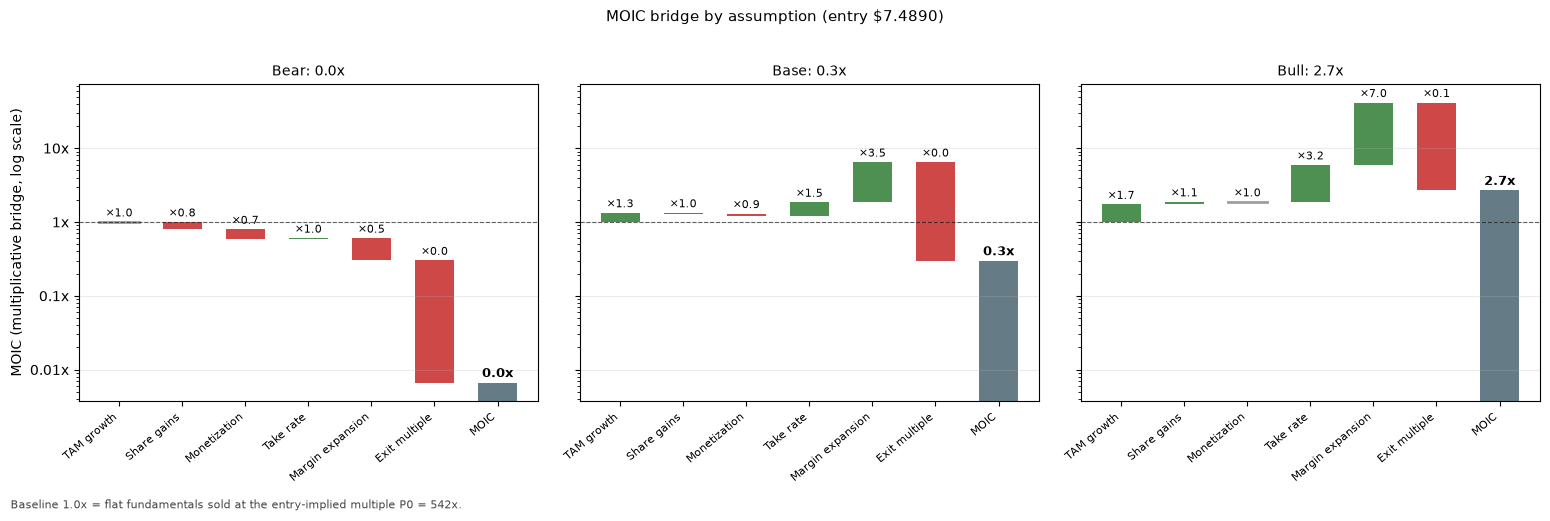

In [10]:
# Per-case MOIC bridge; bars multiply to the case MOIC (asserted).
_wf = {c: model.moic_waterfall(c, scenario, ctx, marks_now, summary['returns_entry'])
       for c in CASES}
for _c, (_df, _m) in _wf.items():
    assert abs(_df['cum_moic'].iloc[-1] - val.loc[_c, 'moic']) < 1e-9 * max(1.0, val.loc[_c, 'moic'])

fig = display.moic_waterfall_chart({c: df for c, (df, _m) in _wf.items()},
                                   summary['returns_entry'],
                                   meta={c: m for c, (_df, m) in _wf.items()})

# factor table behind the bars
_ft = pd.DataFrame({c: [f'x{f:.2f}' for f in _wf[c][0]['factor']] for c in CASES},
                   index=list(_wf[CASES[0]][0]['step']))
_ft.loc['MOIC (product)'] = [f"{val.loc[c, 'moic']:.1f}x" for c in CASES]
print('MOIC bridge factors by case')
_ft

## Comps

Uniswap is a spot exchange, so the comp set is built around that. Exchanges and market infrastructure (CME, ICE, NDAQ, CBOE) show what a mature, fee-taking venue is worth on its earnings. Crypto-adjacent equities (COIN, HOOD) show what the market pays for crypto trading revenue. Token peers (Hyperliquid, Aerodrome, PancakeSwap, Raydium, Curve) are the closest read on how onchain venues are priced. All figures TTM, everything at spot, levels and multiples on FDV (mcap alongside; equities' FDV is proxied by market cap, no EV).

FDV/EBITDA is the tie-out column for the model: it is the basis of `exit_pe` and of the section-4 entry multiple, and EBITDA Mgn anchors the model's margin ramp. The base exit multiple of 25x sits between the exchange median of 15.0x and the crypto-adjacent median of 42.1x. It carries a premium to exchanges for volume growth and a discount to crypto-adjacent names because UNI's EBITDA is a modelled proxy, not a reported number. Bear at 12x is a de-rating to mature-exchange levels (CME 16.4x, ICE 11.4x). Bull at 35x stays below the crypto-adjacent median. Revenue is the NET take everywhere: total revenue for equities, DeFiLlama net protocol revenue for tokens + the subject (same altitude as the model's revenue line). Tokens do not report opex, so their EBITDA is blank and their read is FDV/Rev.

Caveats. UNI trades at 38.0x Mcap/Revenue (54x FDV on the $123m run-rate, 117x FDV on TTM revenue) against a token-peer median of 10.9x, because the fee switch was live for only part of the trailing year. Only Curve (31.4x) and Hyperliquid (25.0x) come close. Hyperliquid revenue includes perps, not only spot. UNI's EBITDA is a proxy: burn revenue less the 20M UNI per year Labs growth budget. Uniswap books no protocol revenue beyond the UNI burn, so revenue and holder revenue coincide.

In [11]:
# Subject row from live marks, at spot like every comp (the entry story lives in
# section 4). Rev = TTM net revenue; EBITDA blank (model assumption, not reported).
subject = dict(Company=f'{PROTOCOL_NAME} ({TICKER})', Group='SUBJECT', Price=PRICE_NOW,
               Mcap=marks_now['mcap'], Fdv=FDV_NOW,
               Rev=ttm_inc['revenue'] if ttm_inc else marks_now['revenue'],
               EBITDA=float('nan'),
               # 12mo = trailing 90 completed days x 365/90 (DeFiLlama daily series)
               Rev90Ann=marks.trailing_ann_mm(DEFILLAMA_SLUG, 'dailyRevenue', 90),
               HolderRev90Ann=marks.trailing_ann_mm(DEFILLAMA_SLUG, 'dailyHoldersRevenue', 90))

print('Pulling comps (yfinance + DeFiLlama + CoinGecko)...')
comps_df = comps.build_comps(subject, EQUITY_COMPS, PEER_COMPS)
print('done.\n')
print('COMPS ($m) - all at spot; levels and multiples on FDV (equities: mcap as the FD proxy)')
print('   Revenue: total revenue for equities, TTM net protocol revenue for tokens + subject.')
print('   FDV/EBITDA is the tie-out to the model exit multiple; blank for tokens (opex unreported).\n')
print('VALUATION COMPS - Mcap multiples; 12mo = trailing 90 days annualized (x 365/90); equities: latest quarter x 4, no holder revenue')
print(display.comps_table_12mo(comps_df, subject_name=PROTOCOL_NAME).to_string())
print('\nLEGACY TTM / EBITDA VIEW (tie-out for the model exit multiple)')
print(display.comps_table(comps_df, subject_name=PROTOCOL_NAME).to_string())
print(f'\nGROUP MEDIANS (ex-{PROTOCOL_NAME})')
print(display.group_median_table(comps_df).to_string())

Pulling comps (yfinance + DeFiLlama + CoinGecko)...
  request failed: JSONDecodeError (bad JSON body, 3 attempts): https://pro-api.llama.fi/***/api/protocol/aerodrome
[comps] Aerodrome: /protocol/aerodrome failed -> TVL / units blank (other fields unaffected)
done.

COMPS ($m) - all at spot; levels and multiples on FDV (equities: mcap as the FD proxy)
   Revenue: total revenue for equities, TTM net protocol revenue for tokens + subject.
   FDV/EBITDA is the tie-out to the model exit multiple; blank for tokens (opex unreported).

VALUATION COMPS - Mcap multiples; 12mo = trailing 90 days annualized (x 365/90); equities: latest quarter x 4, no holder revenue
                                                 Group      Mcap       FDV Mcap/Revenue (12mo) Mcap/Holder Revenue (12mo)
Uniswap (UNI)                                  SUBJECT   $4,686m   $6,645m               38.0x                      38.0x
CME                  Exchanges / market infrastructure  $99,974m  $99,974m               14.

In [12]:
# Cache each token comp's DeFiLlama income statement to data/financial_statements/{slug}.json
# (live pull overwrites; USE_LIVE_DATA=False reads the cache). Needs DEFILLAMA_API_KEY (Pro).
_fin_stmts = comps.fetch_comp_financial_statements(PEER_COMPS, use_live=USE_LIVE_DATA)
for _slug, _d in _fin_stmts.items():
    _yrs = sorted(_d['aggregates']['yearly'])
    print(f"  {_d.get('displayName', _slug):16s} {_yrs[0]}-{_yrs[-1]}  "
          f"-> data/financial_statements/{_slug}.json")

  Hyperliquid      2024-2026  -> data/financial_statements/hyperliquid.json
  Aerodrome        2023-2026  -> data/financial_statements/aerodrome.json
  PancakeSwap      2021-2026  -> data/financial_statements/pancakeswap.json
  Raydium          2022-2026  -> data/financial_statements/raydium.json
  Curve Finance    2020-2026  -> data/financial_statements/curve-finance.json


# Thesis & One-Pager

Reuses the valuation computed above, no recompute. Edit NARRATIVE and MANUAL, then this section writes `outputs/<slug>-one-pager.html` and previews it. For a new token: duplicate the notebook, change the knobs and narrative, Run All.

In [13]:
import yaml
from valuation.pipeline import build_metrics
from onepager import save
from IPython.display import IFrame, display as ipy_display

## Narrative

In [23]:
NARRATIVE = yaml.safe_load(r"""
protocol_name: Uniswap            # EDIT everything in this block
ticker: UNI
sector: DEX
verdict: HOLD           # BUY / ACCUMULATE / HOLD / REDUCE / SELL

# NOTE: any figures quoted in the thesis are hand-written; re-check them against
# the comps table above before sharing (they go stale).
thesis: >-
  Uniswap has been the largest onchain spot exchange since 2018 and has paid
  liquidity providers $6.1b of fees. Annual LP fees were $598m in 2023, $1.09b
  in 2024 and $1.05b in 2025, and none has fallen below $598m since 2021. UNI
  holders saw none of it until the fee switch went live in December 2025. The
  protocol now keeps 7.9% of LP fees and burns all of it, a $123m annualized
  run-rate against $57m over the trailing year. We underwrite a 27% volume
  share, a take rate rising from 8% to 12% and a 35% EBITDA margin, which gives
  $226m of revenue and $79m of EBITDA in FY2029. At 25x, between the exchange
  median of 15x and the crypto-adjacent median of 42x, that is $2.23 a token
  against $7.49 spot. The market already pays 54x run-rate revenue for the
  unlock, so our probability-weighted $6.14 sits 18% below spot and a buy needs
  the bull case, $20.04 on a 25% take rate and 70% margins. The business is
  durable. The price already assumes the fee switch works.

team:    'Hayden Adams (founder, CEO Uniswap Labs) leads Labs, which has shipped v1 through v4, UniswapX and Unichain since 2018.'
market:  'Spot DEX volume is $3.5tn a year; Uniswap routed 21% of it over the trailing year and 28% over the last 30 days.'
product: 'v2, v3 and v4 AMMs, UniswapX and Unichain; protocol fees burn UNI through TokenJar and Firepit.'

overview: >-
  Uniswap is the largest onchain spot exchange, with $79.5bn of volume over the
  last 30 days. LPs earned $129.6m of fees in that window and the protocol kept
  $10.2m. UNIfication (Dec 2025) turned on v2 and v3 protocol fees and burned
  100M UNI from the treasury. Proposal 100 (27 Jul 2026) added v4 pool fees on
  seven chains. About 113M UNI has been burned.

management: >-
  Labs shipped v4, Unichain and the fee rollout on schedule, and UNIfication
  passed with 99.9% of votes.

sentiment: >-
  UNI is up roughly 3x from its June low near $2.43, but the 30d revenue
  run-rate has fallen 37% from its $197m peak on 18 Sep to $123m.

# catalysts & risks: write each line to convey WHEN it lands and WHY it matters for the token
catalysts:
  - 'Q4 2026; v4 fee Part 2 covers the five remaining chains, the cheapest step-up in take rate.'
  - '29 Oct 2026; Unichain migrates to OP Enterprise, and sequencer fees also burn UNI.'
  - '2027; fee-free auctions and hook burns lift take rate without raising LP costs.'

risks:
  - 'Ongoing; the 20M UNI per year growth budget exceeds the roughly 16M UNI per year burn.'
  - 'Any quarter; LP migration to fee-free venues caps the take rate. Flat volume is our bear case.'
  - 'End-2027; the growth budget is up for renewal, and a larger one cuts owner earnings.'

# token economics: fee_switch, token_rights and equity_capture are
# auto-pulled from the DeFiLlama token-rights dataset (see pipeline.build_metrics).

# footer
data_sources: DefiLlama and CoinGecko
""")


## Manual inputs

Position sizing is the only hand-entered input; everything else auto-fills from the valuation above. Use MANUAL only to override a specific figure (e.g. `traction_title`, `comps_note`, or a hand-set table).

In [24]:
# Position sizing; allocation % = notional / fund size.
NOTIONAL_M  = None  # EDIT: $mm deployed; leave None until sized (renders as "n/a")
FUND_SIZE_M = 50    # $mm fund size

MANUAL = dict(      # hand-set overrides only
    comps_note=("Mcap = price x circulating supply; FDV = price x total supply (CoinGecko fully diluted valuation, "
                "not DeFiLlama's Outstanding FDV). Multiples on Mcap. 12mo = trailing 90 days annualized "
                "(x 365/90) from DeFiLlama. Revenue = protocol revenue; Holder Revenue = the share accruing "
                "to token holders (buybacks / burns / staking). Uniswap's two figures coincide: DeFiLlama books "
                "no protocol revenue beyond the UNI burn. Peer row = simple mean of the multiples shown."),
)


## Render & preview

In [25]:
# build_metrics has no defaults: the notebook passes every cfg key it needs.
cfg = dict(base_case=ACTIVE_CASE, defillama_slug=DEFILLAMA_SLUG, gecko_id=GECKO_ID,
           annualize_window_days=ANNUALIZE_WINDOW_DAYS, peer_comps=PEER_COMPS,
           protocol_label=PROTOCOL_NAME, unit_label=UNIT_LABEL, units_metric=UNITS_METRIC)
# One-pager comps columns: Mcap / 12mo revenue and Mcap / 12mo holder revenue (12mo = trailing 90d x 365/90).
cfg['comps_specs'] = [
    dict(col='Revenue (12mo)',        numerator='mcap', subject=marks.trailing_ann_mm(DEFILLAMA_SLUG, 'dailyRevenue', 90),        peer_key='Rev90Ann'),
    dict(col='Holder Revenue (12mo)', numerator='mcap', subject=marks.trailing_ann_mm(DEFILLAMA_SLUG, 'dailyHoldersRevenue', 90), peer_key='HolderRev90Ann'),
]
valuation = dict(cfg=cfg, marks=marks_now, fdv_now=FDV_NOW, scenario=scenario,
                 ctx=ctx, val=val, summary=summary, meta=meta)

NUMBERS = build_metrics(valuation, comps_df=comps_df, manual=MANUAL,
                        notional_m=NOTIONAL_M, fund_size_m=FUND_SIZE_M)
assert NUMBERS['base_moic'] == f"{val.loc[ACTIVE_CASE, 'moic']:,.1f}x"   # ties to the notebook
context = {**NARRATIVE, **NUMBERS}
out = save(context, f"outputs/{DEFILLAMA_SLUG}-one-pager.html")
print("wrote", out)
ipy_display(IFrame(str(out), width=860, height=1120))

wrote outputs/uniswap-one-pager.html
